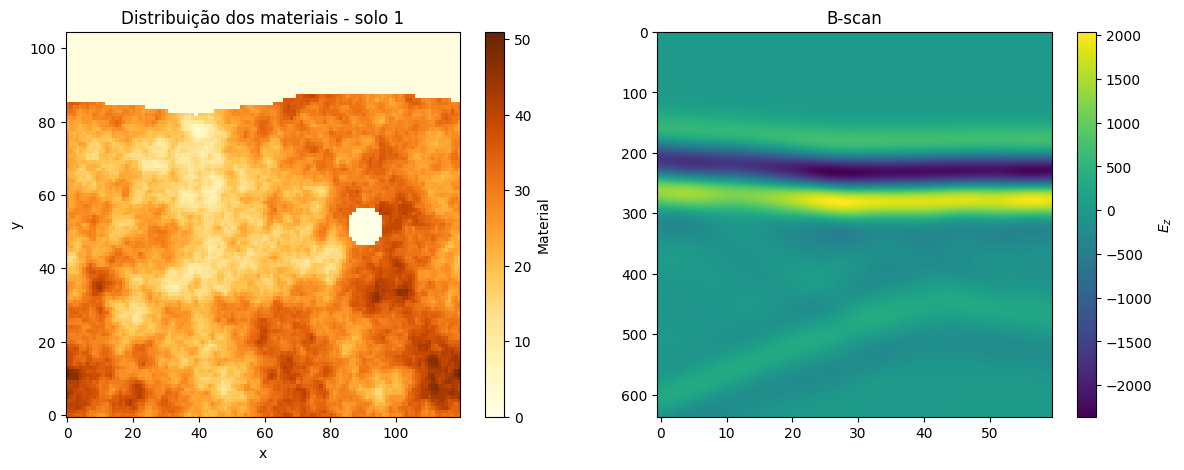

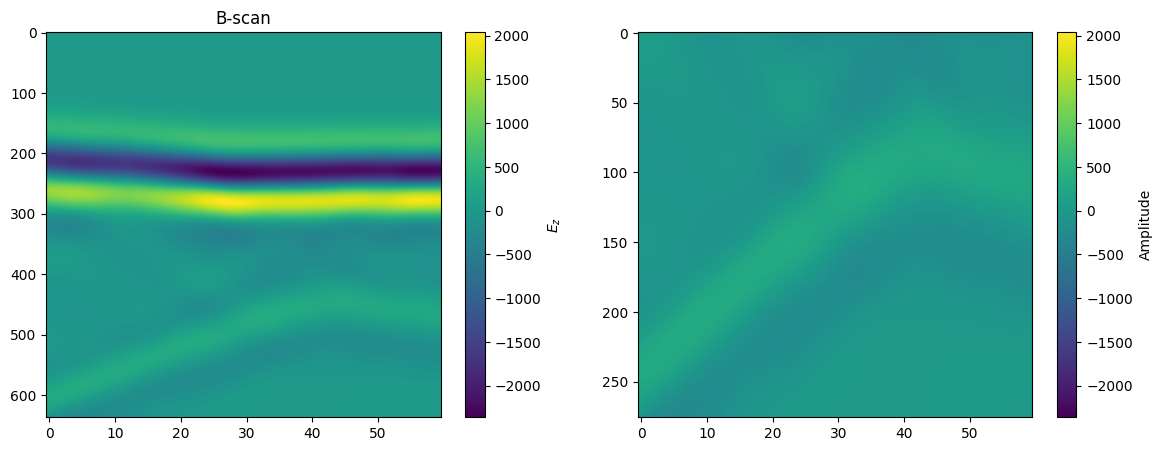

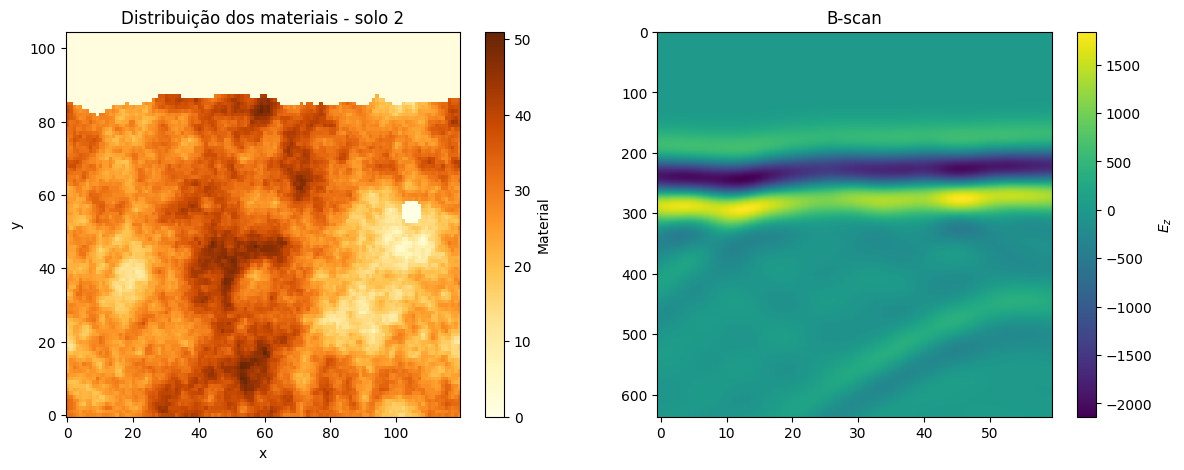

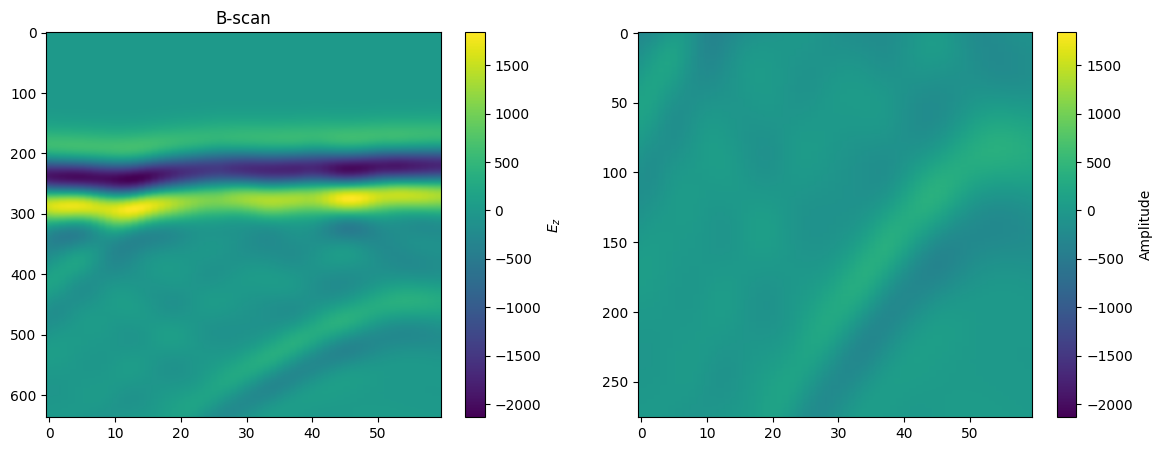

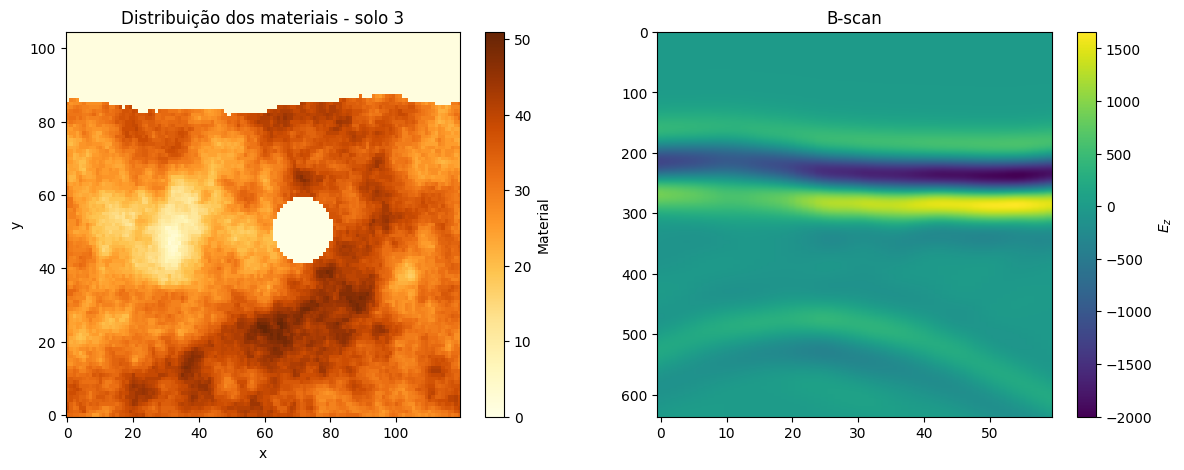

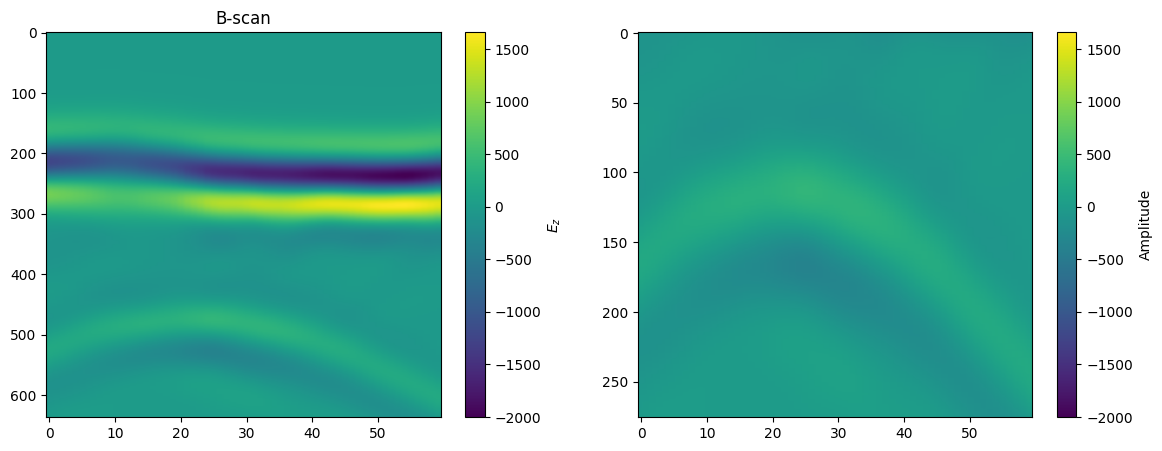

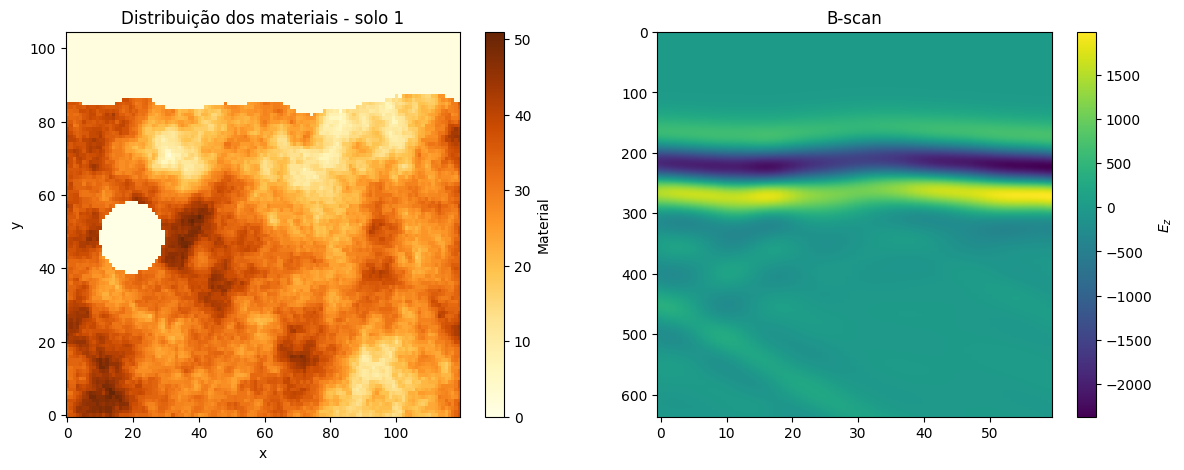

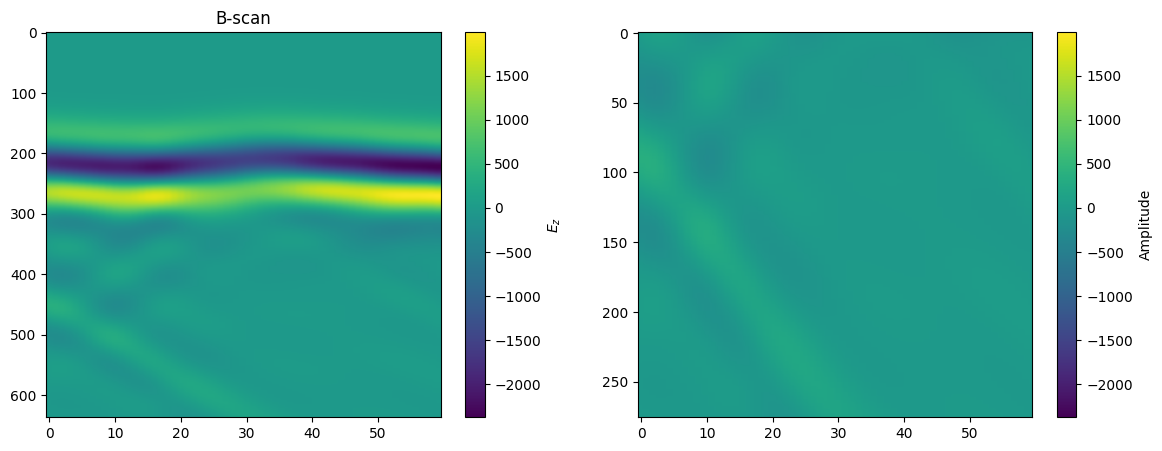

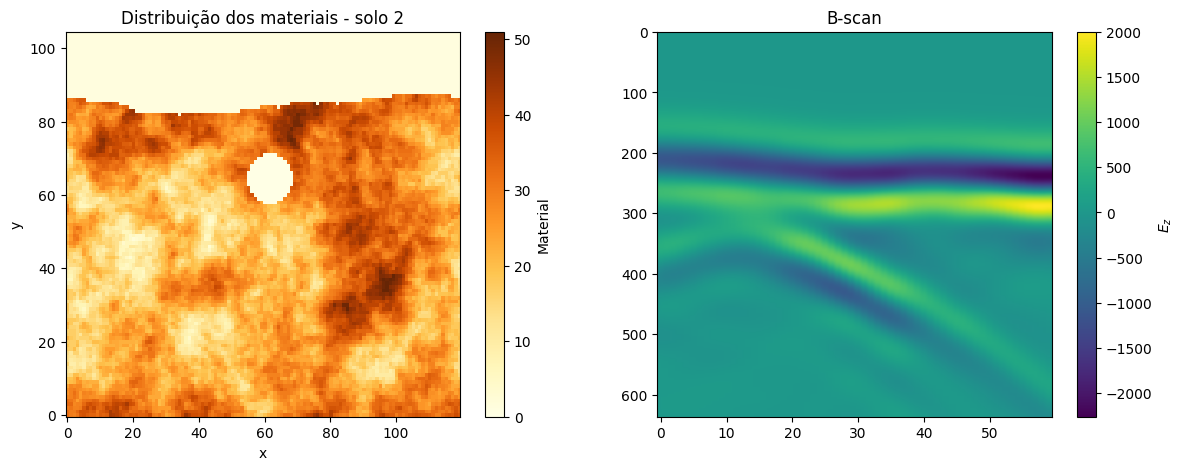

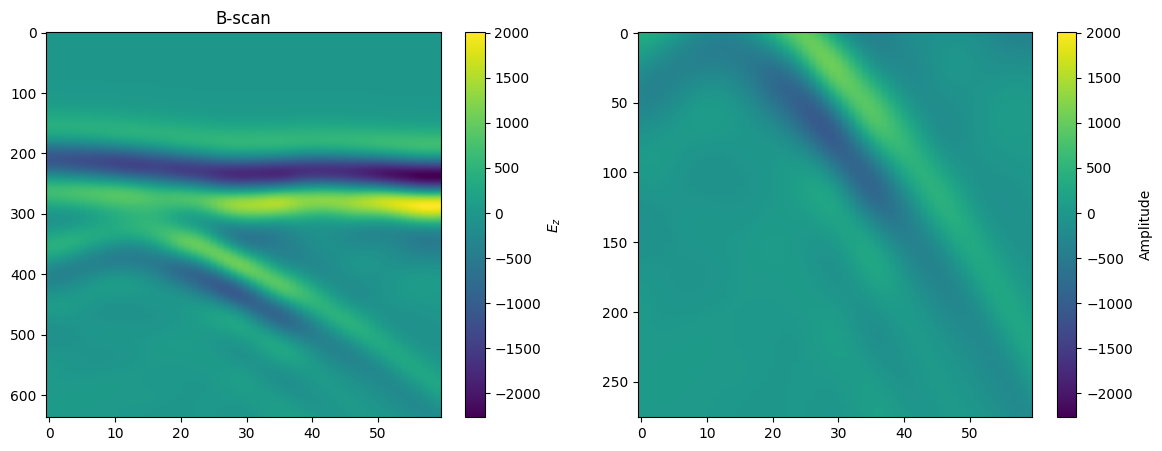

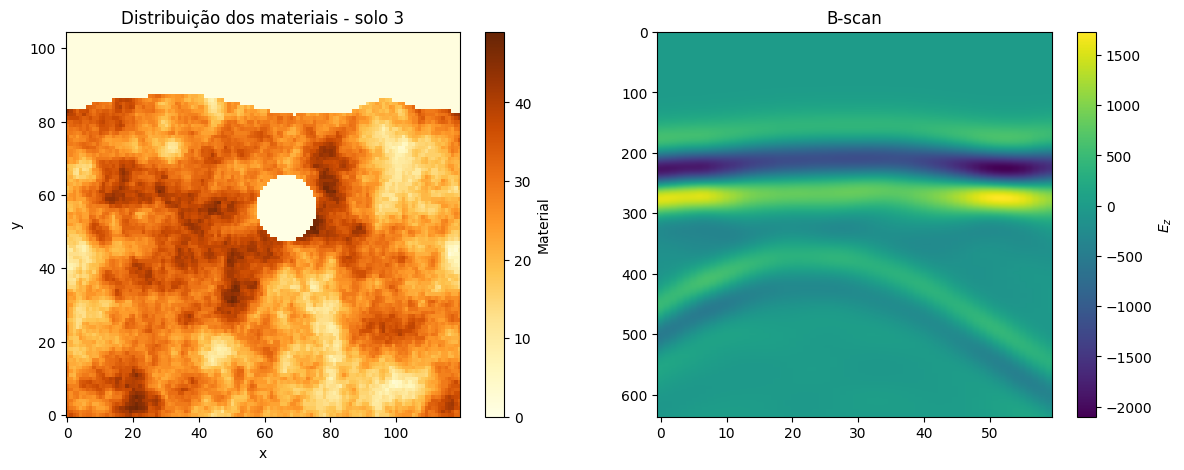

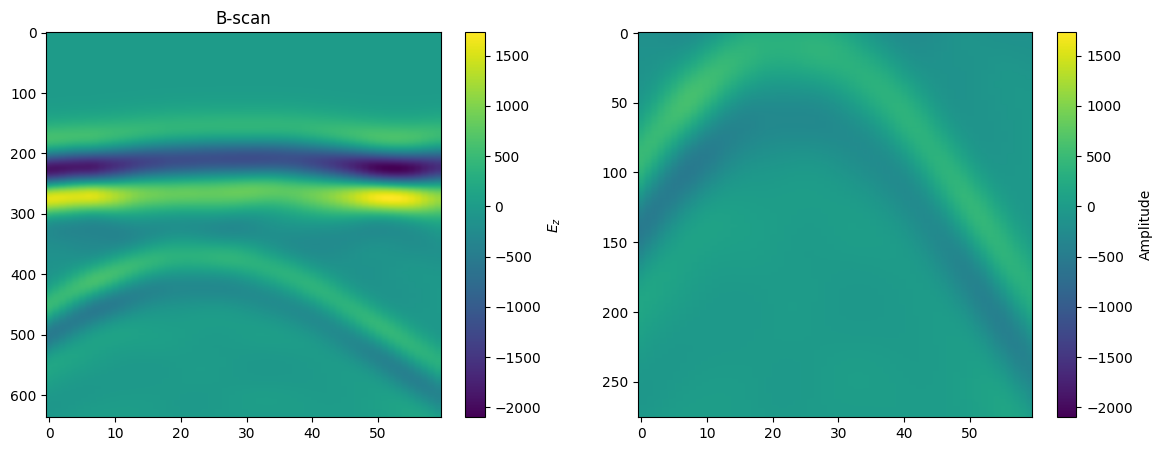

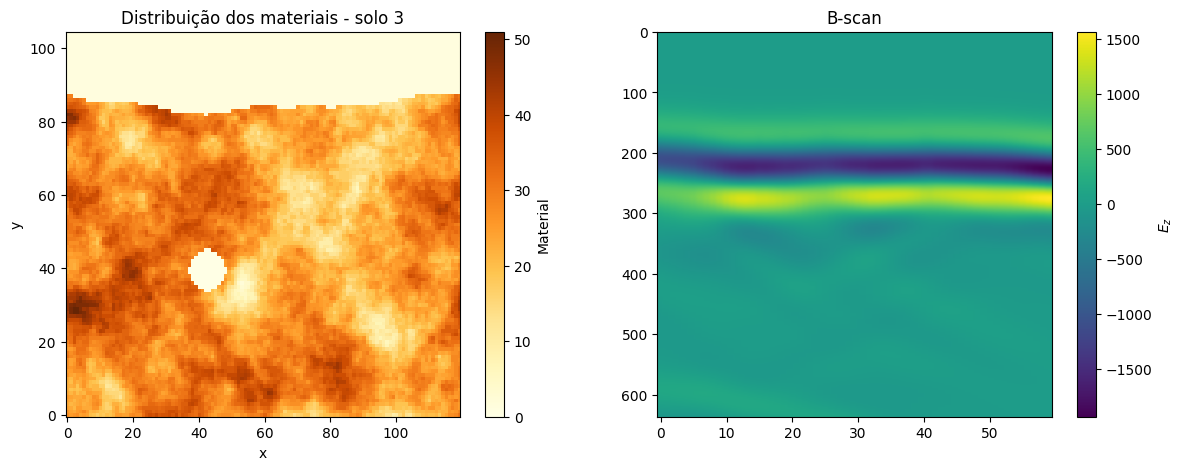

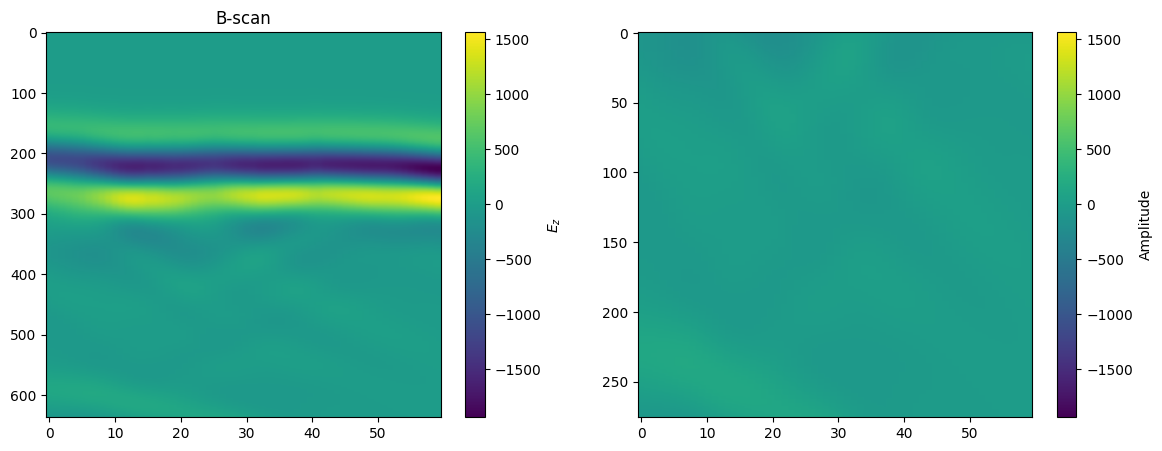

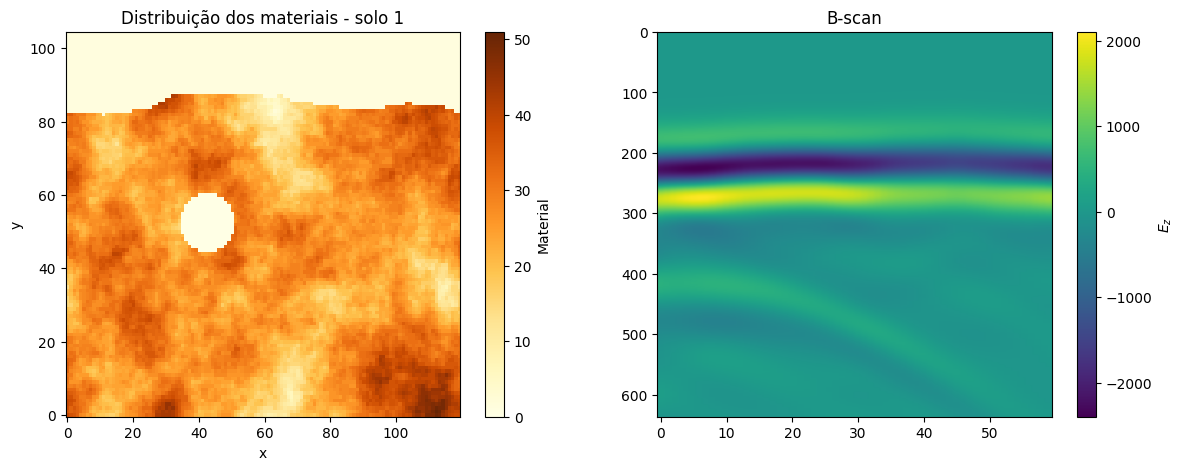

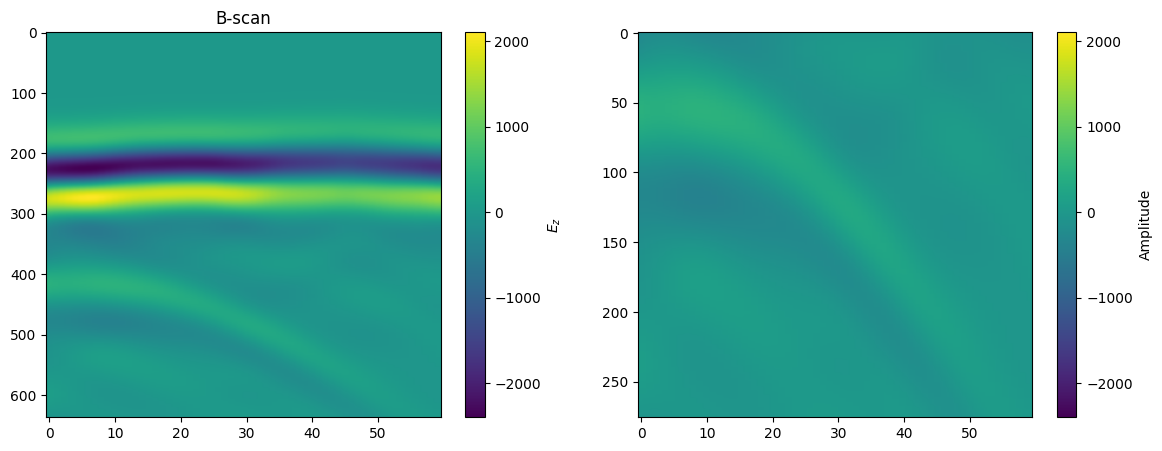

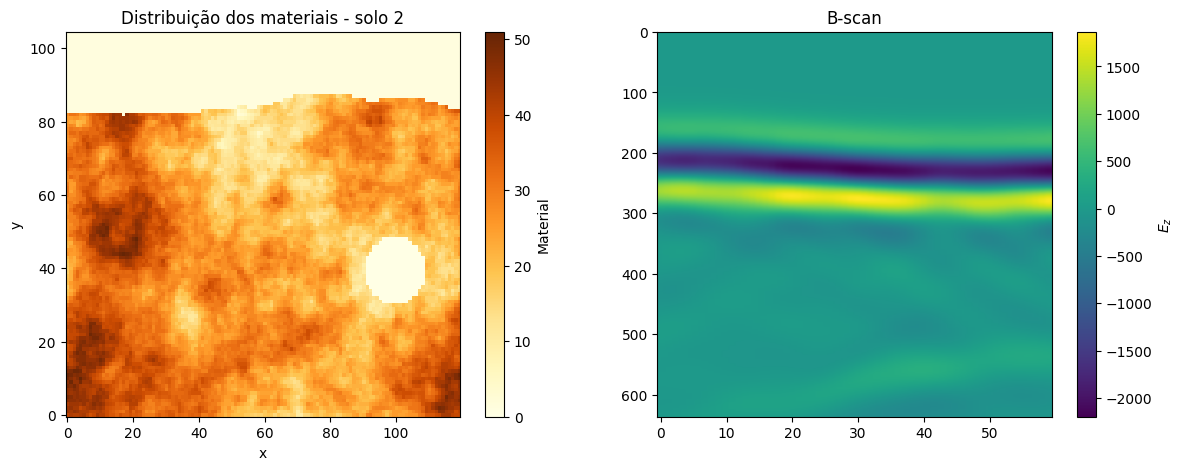

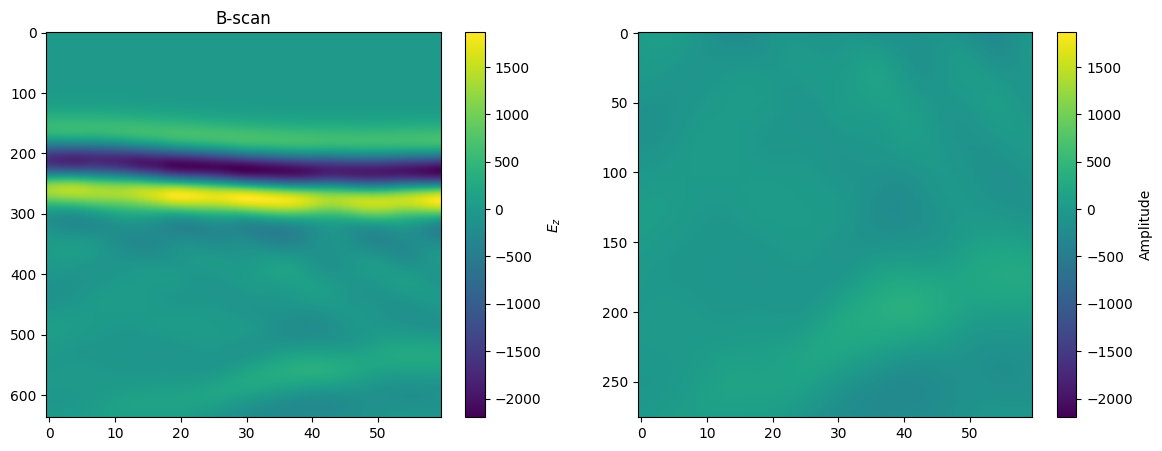

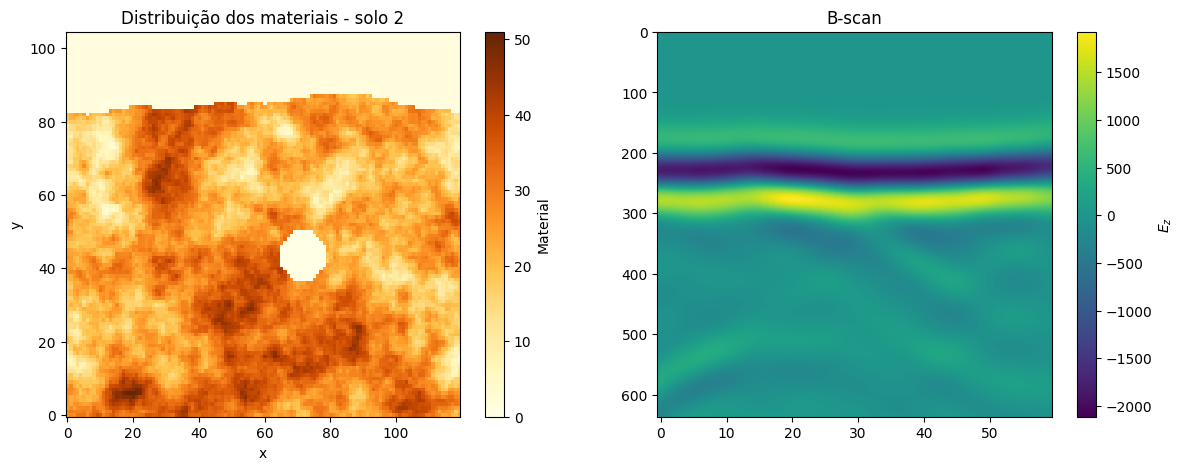

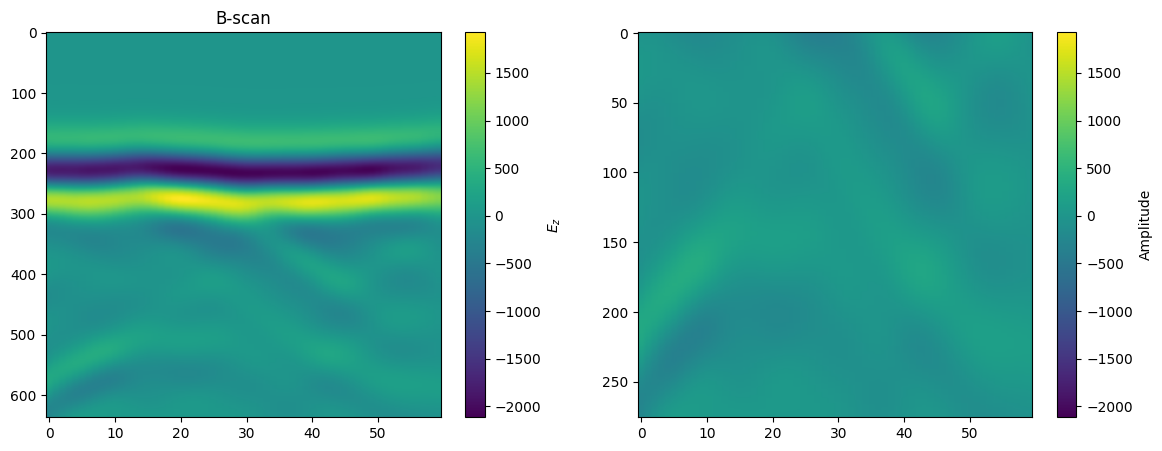

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
import pandas as pd

N = 10
Nf = 360

labels = pd.read_csv('labels1-10.csv')
solos = labels['soil_type']

for i in range(1,N+1):
    with h5py.File(f'Bscan{i}__merged.out', 'r') as f:
        rx = f['rxs/rx1']
        ez = rx['Ez'][:]

    # Recorte da região de interesse - ROI
    ez_corr = ez[Nf + 1:637, 0:60]

    arquivo = rf"solo{i}.vti"
    dados = pv.read(arquivo)
    material = dados.cell_data["Material"]
    nx, ny, nz = dados.dimensions
    imagem = material.reshape(nz - 1, ny - 1, nx - 1)[0]


    fig, ax = plt.subplots(1,2,figsize=(14,5))
    im1 = ax[1].imshow(ez,cmap='viridis',aspect='auto')
    ax[1].set_title('B-scan')
    fig.colorbar(im1, ax=ax[1], label=r'$E_z$')

    # im1 = ax[1].imshow(ez_corr,cmap='viridis',aspect='auto')#,vmin=ez.min(),vmax=ez.max())
    # fig.colorbar(im1, ax=ax[1], label='Amplitude')

    im0 = ax[0].imshow(imagem, origin="lower", aspect="auto", cmap="YlOrBr")
    fig.colorbar(im0, ax=ax[0], label="Material")
    ax[0].set_xlabel("x")
    ax[0].set_ylabel("y")
    ax[0].set_title(f"Distribuição dos materiais - solo {solos[i-1]}")

    # plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(1,2,figsize=(14,5))
    im0 = ax[0].imshow(ez,cmap='viridis',aspect='auto')
    ax[0].set_title('B-scan')
    fig.colorbar(im0, ax=ax[0], label=r'$E_z$')

    im1 = ax[1].imshow(ez_corr,cmap='viridis',aspect='auto',vmin=ez.min(),vmax=ez.max())
    fig.colorbar(im1, ax=ax[1], label='Amplitude')
    plt.show()
